#Introducere în Machine Learning


###Laboratorul 1

 Sarcini practice bazate pe setul de date Iris.csv

- Pandas https://pandas.pydata.org/docs/,
- Matplotlib https://matplotlib.org/,
- Seaborn https://seaborn.pydata.org/,
- Intel Extension for Scikit-learn https://uxlfoundation.github.io/scikit-learn-intelex/latest/index.html

### Exercițiul 1: Încărcarea și analiza inițială a datelor

Folosind bibliotecile pandas și numpy, încărcați fișierul Iris_Data.csv din directorul data. Afișați pe ecran:
 - Numărul total de rânduri.
 - Numele tuturor coloanelor.
 - Tipurile de date pentru fiecare coloană.

In [1]:
import os
import numpy as np
import pandas as pd

# Directorul cu date (în Colab fișierul poate fi și în rădăcină)
DATA_DIR = 'data' if os.path.isdir('data') else '.'
df = pd.read_csv(os.path.join(DATA_DIR, 'Iris_Data.csv'))

print("Numărul total de rânduri:", len(df))
print("\nNumele coloanelor:", df.columns.tolist())
print("\nTipurile de date:")
print(df.dtypes)

Numărul total de rânduri: 150

Numele coloanelor: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

Tipurile de date:
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species             str
dtype: object


###Exercițiul 2: Curățarea și transformarea datelor text

Explorați valorile din coloana species.
Observați că toate încep cu prefixul Iris-.

Scrieți cod pentru a elimina acest prefix din toate rândurile (astfel încât să rămână doar setosa, versicolor, virginica).

In [2]:
print("Valori înainte:", df['species'].unique())
df['species'] = df['species'].str.replace('Iris-', '', regex=False)
print("Valori după  :", df['species'].unique())
df.head()

Valori înainte: <StringArray>
['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
Length: 3, dtype: str
Valori după  : <StringArray>
['setosa', 'versicolor', 'virginica']
Length: 3, dtype: str


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


### Exercițiul 3: Statistica descriptivă și amplitudinea (range)

Folosind metoda describe()creați un rând nou în tabel numit range, care calculează diferența dintre valoarea maximă și valoarea minimă pentru fiecare coloană numerică.

In [3]:
stats = df.describe()
stats.loc['range'] = stats.loc['max'] - stats.loc['min']
stats

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000
range,3.600000,2.400000,5.900000,2.400000


### Exercițiul 4: Grupatarea datelor pe specii (Media și Mediana)
 Grupați setul de date după coloana species  și aplicați simultan funcțiile de medie (mean)și mediană (median) pentru toate coloanele numerice.

In [4]:
df.groupby('species').agg(['mean', 'median'])

sepal_length        sepal_width        petal_length         \
                   mean median        mean median         mean median   
species                                                                 
setosa            5.006    5.0       3.418    3.4        1.464   1.50   
versicolor        5.936    5.9       2.770    2.8        4.260   4.35   
virginica         6.588    6.5       2.974    3.0        5.552   5.55   

           petal_width         
                  mean median  
species                        
setosa           0.244    0.2  
versicolor       1.326    1.3  
virginica        2.026    2.0

### Exercițiul 5: Agregare avansată utilizând un dicționar

Folosind metoda agg() pentru datele grupate
aplicați următoarele reguli: pentru sepal_length, sepal_width și petal_width calculați media și mediana, iar pentru petal_length — doar valoarea maximă (max).

In [5]:
df.groupby('species').agg({
    'sepal_length': ['mean', 'median'],
    'sepal_width':  ['mean', 'median'],
    'petal_width':  ['mean', 'median'],
    'petal_length': 'max'
})

sepal_length        sepal_width        petal_width         \
                   mean median        mean median        mean median   
species                                                                
setosa            5.006    5.0       3.418    3.4       0.244    0.2   
versicolor        5.936    5.9       2.770    2.8       1.326    1.3   
virginica         6.588    6.5       2.974    3.0       2.026    2.0   

           petal_length  
                    max  
species                  
setosa              1.9  
versicolor          5.1  
virginica           6.9

### Exercițiul 6: Vizualizarea datelor cu ajutorul Matplotlib

Importați matplotlib.pyplot și construiți un diagramă de dispersie (scatter plot) care reflectă dependența dintre sepal_length (axa X) și sepal_width (axa Y).
   Adăugați etichete pentru axe și un titlu.

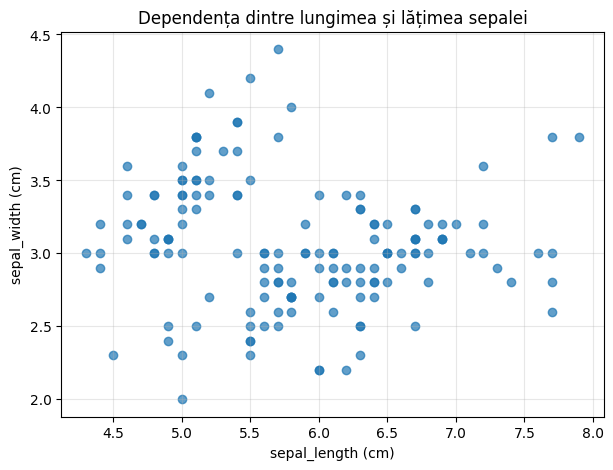

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
plt.scatter(df['sepal_length'], df['sepal_width'], alpha=0.7)
plt.xlabel('sepal_length (cm)')
plt.ylabel('sepal_width (cm)')
plt.title('Dependența dintre lungimea și lățimea sepalei')
plt.grid(alpha=0.3)
plt.show()

### Exercițiul 7: Numărarea frecvenței speciilor
 Folosiți o metodă specială din Pandas pentru a afla numărul exact de înregistrări pentru fiecare specie în parte din setul de date curățat.

In [7]:
df['species'].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

### Exercițiul 8: Accelerarea Scikit-learn folosind Intel® Extension

Scrieți liniile de cod care trebuie executate imediat după importarea bibliotecii sklearn pentru a activa optimizarea oneDAL

In [8]:
# Dacă rulați în Google Colab, decomentați linia de mai jos:
# !pip install scikit-learn-intelex

import sklearn
from sklearnex import patch_sklearn
patch_sklearn()   # activează optimizările oneDAL pentru algoritmii sklearn compatibili

Extension for scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


### Exercițiul 9: Framework-uri în Machine Learning\

Bazându-vă pe materialele introductive, explicați de ce framework-urile sunt mai mult decât simple biblioteci și ce beneficiu material aduce optimizarea hiperparametrilor.

**Răspuns.**

**Framework-uri vs. biblioteci.** O *bibliotecă* (de ex. NumPy, Pandas) este o colecție de funcții pe care **noi** le apelăm când avem nevoie: controlul programului rămâne la noi. Un *framework* (de ex. scikit-learn ca ecosistem, TensorFlow, PyTorch) impune o **structură de lucru** și un ciclu de viață al proiectului (încărcare date → preprocesare → antrenare → evaluare → ajustare → punere în producție); codul nostru se „încadrează” în această structură (principiul *inversării controlului*). Un framework oferă în plus:
- o interfață unitară (`fit` / `predict` / `transform`) care permite înlocuirea ușoară a modelelor;
- conducte (`Pipeline`), validare încrucișată și căutare de hiperparametri integrate;
- reproductibilitate, standardizare și optimizări de performanță (paralelizare, accelerare hardware);
- un ecosistem de instrumente și o comunitate în jurul lui.

**Beneficiul material al optimizării hiperparametrilor.** Hiperparametrii (de ex. numărul de vecini K, adâncimea unui arbore, rata de învățare) nu se învață din date, ci se fixează înainte de antrenare. Alegerea lor corectă:
- crește **acuratețea și capacitatea de generalizare** a modelului fără a colecta date suplimentare;
- reduce riscul de **subantrenare / supraantrenare** (de ex. K prea mic → overfitting, K prea mare → underfitting);
- **economisește resurse**: un model mai bun cu aceleași date și aceeași arhitectură înseamnă mai puține greșeli costisitoare în aplicația reală (decizii de business, diagnostic etc.) și mai puțin timp de încercări manuale;
- poate fi **automatizată** (GridSearchCV, RandomizedSearchCV, Optuna).

### Exercițiul 10: Cerințe preliminare ale cursului
  Enumerați cel puțin trei direcții de bază  (în matematică și programare) necesare pentru parcurgerea cu succes a cursului de Machine Learning

**Răspuns – cerințe preliminare ale cursului:**

*Matematică*
1. **Algebră liniară** – vectori, matrice, norme și distanțe, produs scalar, valori/vectori proprii (baza reprezentării datelor și a PCA).
2. **Analiză matematică** – derivate, gradient, optimizare (baza antrenării prin gradient descent).
3. **Teoria probabilităților și statistică** – distribuții, medie, dispersie, corelație, estimare, teste (baza evaluării și a modelelor probabilistice).

*Programare*
4. **Python** – structuri de date, funcții, clase, lucrul cu fișiere.
5. **Biblioteci pentru date** – NumPy, Pandas, Matplotlib/Seaborn și scikit-learn.
6. Noțiuni de lucru cu **Jupyter/Colab** și **Git** (reproductibilitatea experimentelor).

### Exercițiul 11: Vizualizarea avansată a distribuțiilor cu Matplotlib (Histograme)
 Folosind Matplotlib, construiți o figură cu două subgrafice (subplots) alături unul de celălalt (1 rând, 2 coloane):
 - Pe primul grafic afișați histogramei de distribuție pentru petal_length.
 - Pe al doilea grafic afișați histogramei de distribuție pentru petal_width.

 Adăugați titluri și etichete la axe pentru fiecare grafic.

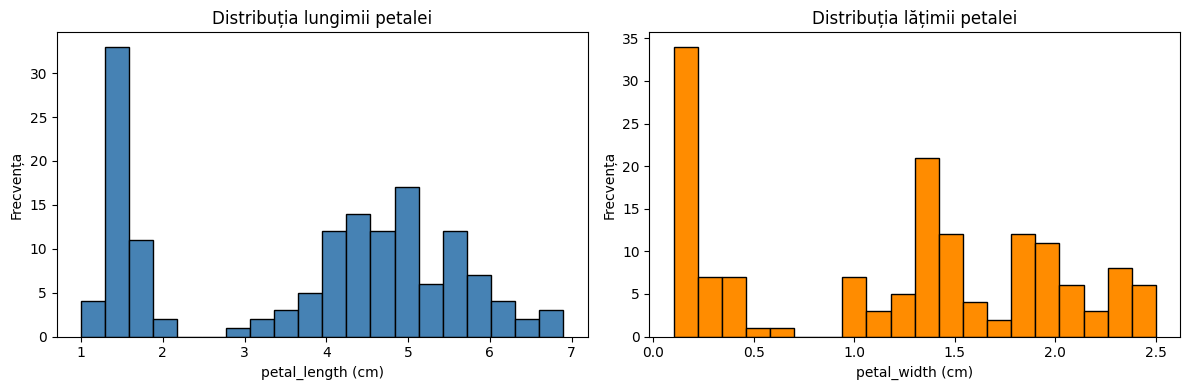

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df['petal_length'], bins=20, color='steelblue', edgecolor='black')
axes[0].set_title('Distribuția lungimii petalei')
axes[0].set_xlabel('petal_length (cm)')
axes[0].set_ylabel('Frecvența')

axes[1].hist(df['petal_width'], bins=20, color='darkorange', edgecolor='black')
axes[1].set_title('Distribuția lățimii petalei')
axes[1].set_xlabel('petal_width (cm)')
axes[1].set_ylabel('Frecvența')

plt.tight_layout()
plt.show()

### Exercițiul 12: Explorarea datelor cu ajutorul Seaborn (Pairplot)

Importați biblioteca seaborn și construiți o matrice de grafice perechi (sns.pairplot)  pentru întregul set de date Iris, colorând punctele în funcție de specia plantei (species).

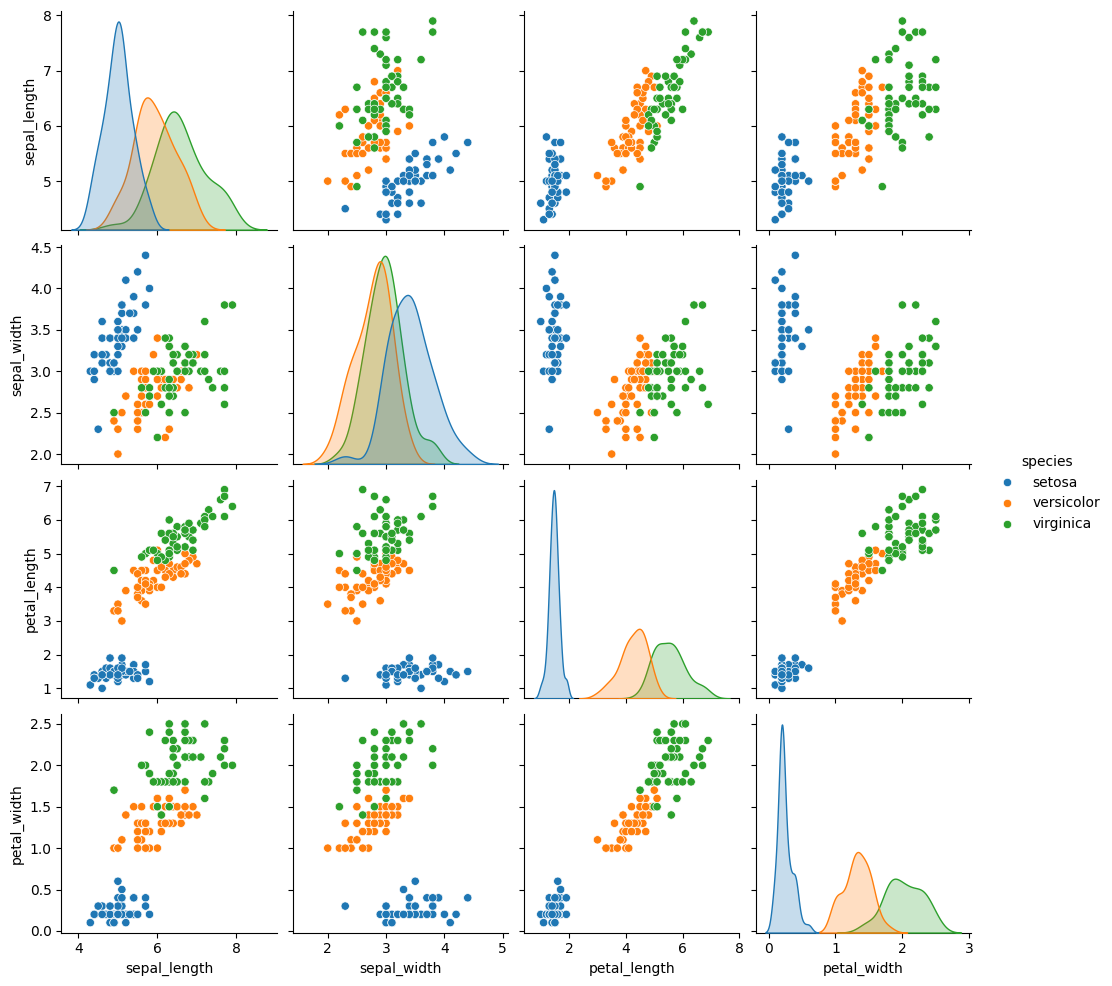

In [10]:
import seaborn as sns

sns.pairplot(df, hue='species')
plt.show()

### Exercițiul 13: Analiza valorilor aberante prin Boxplot (Seaborn)

Folosind biblioteca Seaborn, construiți un diagramă box-and-whisker (sns.boxplot), pentru a compara distribuția lungimii petalelor (petal_length) pentru fiecare specie în parte (species).

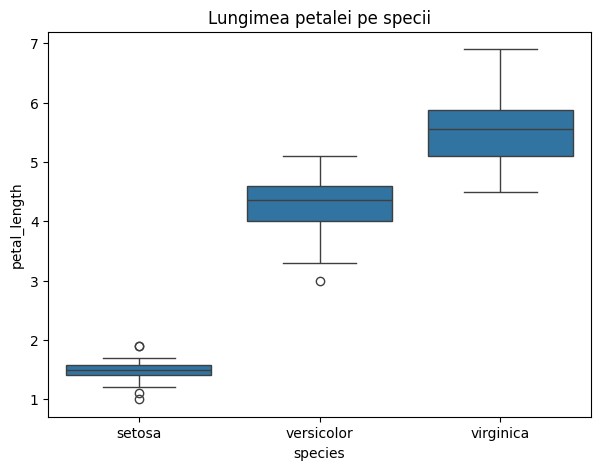

In [11]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x='species', y='petal_length')
plt.title('Lungimea petalei pe specii')
plt.show()

### Exercițiul 14: Harta termică a corelațiilor (Seaborn Heatmap)
 Calculați matricea de corelație a caracteristicilor numerice folosind metoda corr(), iar apoi vizualizați-o sub formă de hartă termică (sns.heatmap), incluzând afișarea valorilor numerice în interiorul celulelor (annot=True).

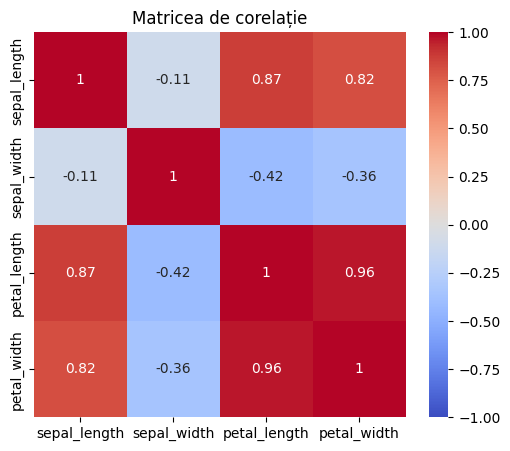

In [12]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matricea de corelație')
plt.show()